In [44]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random

%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

In [3]:
f(3.0)

20.0

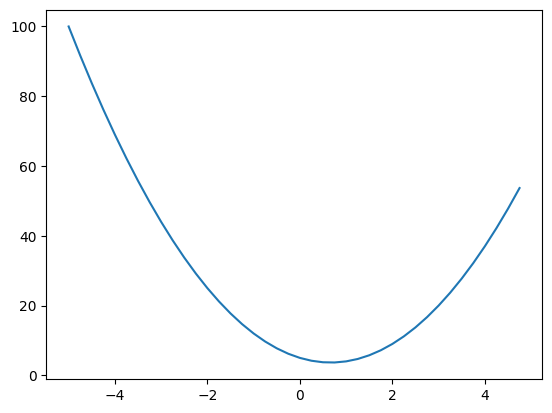

In [4]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [5]:
class Value:
    
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._backward = lambda: None
        self._op = _op
        self.label = label
        
    def __repr__(self):
        return f"Value(data={self.data})" 
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0*out.grad
            other.grad += 1.0*out.grad
        out._backward = _backward
        return out

    def __radd__(self, other):
        return self + other
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)

        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += out.grad*other.data
            other.grad += out.grad*self.data
        out._backward = _backward
        return out

    def __rmul__(self, other):
        return self * other

    def __neg__(self): # -self
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __truediv__(self, other):
        return self * other**-1

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out = Value (self.data**other, (self,), f'**{other}')

        def _backward():
            n = other
            self.grad += n*(self.data**(n-1)) * out.grad

        out._backward = _backward

        return out

    def exp(self):
        #double check
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad = out.data * out.grad
        
        out._backward = _backward
        return out

    def tanh(self):
        n = self.data
        t = ( math.exp(2*n)- 1 ) / ( math.exp(2*n) + 1)
        def _backward():
            self.grad += (1-(t*t)) * out.grad

        
        out = Value(t , (self, ), 'tanh')


        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [6]:
from graphviz import Digraph
import os

os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"

def trace(root):
    #builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) #LR = left to right
    
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}"% (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if the value is the result of an operation, create an op node for it
            dot.node(name= uid + n._op, label = n._op)
            #and connect this node to it
            dot.edge(uid + n._op, uid)
            
    for n1, n2 in edges:
        #connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
        
    return dot


In [12]:
x1 = Value(2.0, label='x1')
x2 = Value(0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1, label='w2')
b = Value(6.881317358, label='b')

x1w1 = x1 * w1 ; x1w1.label = 'x1*w1'
x2w2 = x2 * w2 ; x2w2.label = 'x2*w2'

x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label = 'x1*w1+x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'


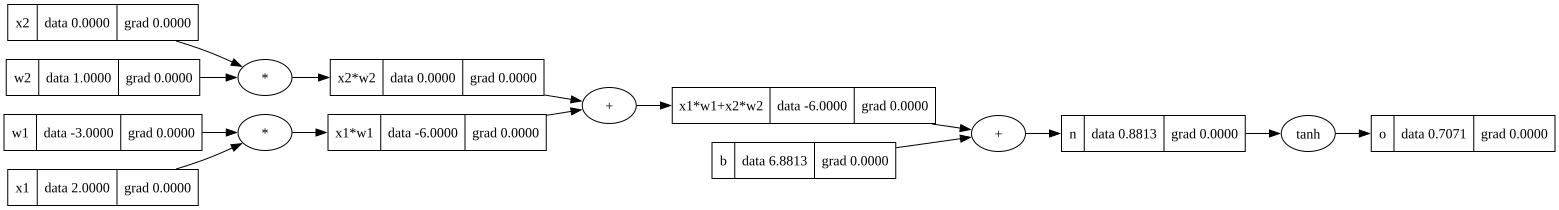

In [13]:
draw_dot(o)

In [14]:
o.backward()

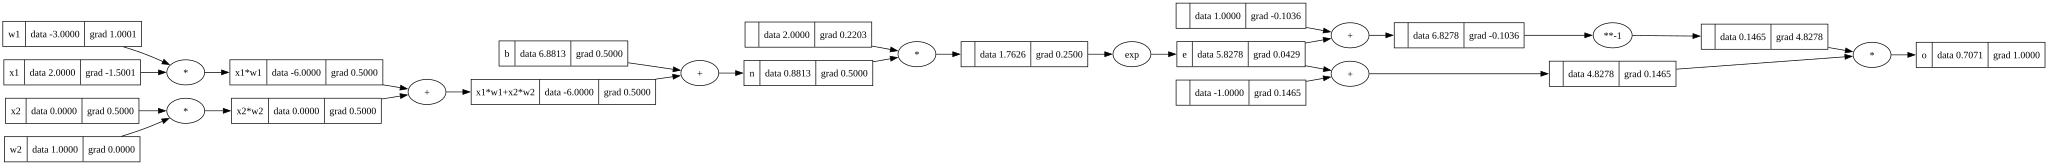

In [17]:
x1 = Value(2.0, label='x1')
x2 = Value(0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1, label='w2')
b = Value(6.881317358, label='b')

x1w1 = x1 * w1 ; x1w1.label = 'x1*w1'
x2w2 = x2 * w2 ; x2w2.label = 'x2*w2'

x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label = 'x1*w1+x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

e = (2*n).exp() ; e.label = 'e'
o = (e - 1) / (e + 1)

o.label = 'o'
o.backward()
draw_dot(o)

In [16]:
import torch

In [76]:

class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        act = sum( (wi*xi for wi, xi in zip(self.w, x)) , self.b) 
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else  outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]



In [155]:
x = [2.0, 3.0, -1.]
n = MLP(3, [4,4,1])
n(x)

Value(data=-0.6228781492282207)

In [156]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
    ]

ys = [1.0, -1.0, -1.0, 1.0]

In [ ]:
for k in range(10):
    #forward pass
    ypred = [n(x) for x in xs]
    loss = sum((yout-ygt)**2 for ygt, yout in zip (ys, ypred))

    #backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    #update for gradient
    for p in n.parameters():
        p.data += -0.1 * p.grad

    print(k, loss.data)

xs